# MERGE — perguntas 2 a 5

Neste notebook compreendemos os dados, fazemos a análise exploratória e tratamos problemas de qualidade antes de estudar a distribuição das classes. O teste oficial é separado logo no início e não é usado para orientar estas decisões; a secção 3.5 apenas verifica a partilha de artistas.

In [40]:
from pathlib import Path
from IPython.display import display #biblioteca para exibir objetos no Jupyter Notebook
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

data_dir = Path.cwd() / "dataset" / "build" / "MERGE_ECAC" / "merge_ecac"
media_dir = Path.cwd() / "dataset"
metadata = pd.read_csv(data_dir / "metadata.csv")
av_values = pd.read_csv(data_dir / "av_values.csv")
test_ids = set(pd.read_csv(data_dir / "test_songs.csv")["Audio_Song"])
if not test_ids.issubset(set(metadata["Audio_Song"])):
    raise ValueError("Há músicas de teste ausentes de metadata.csv.")

test_mask = metadata["Audio_Song"].isin(test_ids) # Cria uma máscara para identificar as linhas que correspondem às músicas de teste
development = metadata.loc[~test_mask].copy().reset_index(drop=True) # isto server para separar o conjunto de desenvolvimento do conjunto de teste
test = metadata.loc[test_mask].copy().reset_index(drop=True) # tem a função de separar o conjunto de teste do conjunto de desenvolvimento

print(f"Metadata: {len(metadata)} linhas | desenvolvimento: {len(development)} | teste: {test['Audio_Song'].nunique()} músicas únicas") #imprime o número de linhas do metadata, desenvolvimento e teste
print("Quadrantes no desenvolvimento:")
display(development["Quadrant"].value_counts().sort_index().to_frame("número de linhas"))

Metadata: 1348 linhas | desenvolvimento: 932 | teste: 409 músicas únicas
Quadrantes no desenvolvimento:


,número de linhas
Quadrant,
Q1,374
Q2,112
Q3,356
Q4,90


**Interpretação:** separámos primeiro as músicas de teste. As restantes contagens usam apenas o conjunto de desenvolvimento, mantendo no mesmo conjunto as linhas repetidas de cada música.

## 2. Compreensão dos dados

### 2.1 Colunas

A tabela resume o tipo, os valores em falta e os valores distintos de cada coluna. As descrições seguem o dicionário de dados.

In [41]:
meaning = {
    "Audio_Song": "ID do áudio", "Lyric_Song": "ID da letra", "Quadrant": "alvo",
    "AllMusic Id": "ID todasmusicas", "AllMusic Extraction Date": "data da extracao todas",
    "Artist": "artista", "Title": "título", "Relevance": "relevância todasmusicas",
    "Year": "ano", "LowestYear": "data mais antiga", "Duration": "duração (s)",
    "Moods": "etiquetas de humor", "MoodsAll": "etiquetas de humor completas",
    "MoodsAllWeights": "pesos de MoodsAll", "Genres": "géneros", "GenreWeights": "pesos de Genres",
    "Themes": "temas", "ThemeWeights": "pesos de Themes", "Styles": "estilos",
    "StyleWeights": "pesos de Styles", "AppearancesTrackIDs": "IDs de outras edições",
    "AppearancesAlbumIDs": "IDs dos álbuns", "Sample": "amostra de música",
    "SampleURL": "endereço da amostra", "ActualYear": "ano usado pelos autores",
    "num_Genres": "número de géneros", "num_MoodsAll": "número de etiquetas de humor",
}

summary = pd.DataFrame({
    "significado": pd.Series(meaning),
    "tipo": development.dtypes.astype(str),
    "em falta (%)": (development.isna().mean() * 100).round(1),
    "distintos": development.nunique(),
})
display(summary)

,significado,tipo,em falta (%),distintos
Audio_Song,ID do áudio,str,0.0,914
Lyric_Song,ID da letra,str,0.0,914
Quadrant,alvo,str,0.0,4
AllMusic Id,ID todasmusicas,str,0.0,911
AllMusic Extraction Date,data da extracao todas,str,0.0,2
Artist,artista,str,0.0,655
Title,título,str,0.0,898
Relevance,relevância todasmusicas,float64,17.2,757
Year,ano,str,12.4,487
LowestYear,data mais antiga,str,34.5,371


**Interpretação:** os IDs ligam os registos e `Quadrant` é a classe que queremos prever. As etiquetas e os respetivos pesos descrevem cada música; as datas de recolha e a disponibilidade de amostras são informação administrativa.

### 2.2 Cruzamento das fontes

O ficheiro `av_values.csv` contém `Arousal` e `Valence` e é ligado à tabela principal pelos IDs da música. O dicionário indica que cada música deve ter áudio e letra; as capas são opcionais. Como as pastas estão organizadas por quadrante, o caminho dos ficheiros revela a classe.

In [42]:
keys = ["Audio_Song", "Lyric_Song"]
joined = development.merge(av_values, on=keys, how="left", validate="many_to_one", indicator=True)
print(f"Pares únicos em metadata: {development[keys].drop_duplicates().shape[0]}")
print(f"Pares encontrados em av_values: {joined[keys + ['Arousal', 'Valence']].drop_duplicates().shape[0]}")
print(f"Linhas repetidas em metadata: {development.duplicated(keys).sum()}")
print(f"Linhas sem correspondência em av_values: {(joined['_merge'] != 'both').sum()}")

media = []
for label, folder, column, extension in [
    ("áudio", "audio", "Audio_Song", ".mp3"),
    ("letras", "lyrics", "Lyric_Song", ".txt"),
    ("capas", "album_covers", "Audio_Song", ".jpg"),
]:
    paths = [p for p in (media_dir / folder).rglob(f"*{extension}") if p.is_file() and not p.name.startswith("._")]
    file_quadrant = {p.stem: p.parent.name for p in paths}
    songs = development[[column, "Quadrant"]].drop_duplicates()
    present = songs[column].isin(file_quadrant)
    wrong = sum(file_quadrant.get(row[column]) != row["Quadrant"] for _, row in songs.loc[present].iterrows())
    media.append({"Fonte": label, "Presente": int(present.sum()), "Faltando": int((~present).sum()), "pasta com quadrante errado": wrong})
display(pd.DataFrame(media))

Pares únicos em metadata: 914
Pares encontrados em av_values: 914
Linhas repetidas em metadata: 18
Linhas sem correspondência em av_values: 0


,Fonte,Presente,Faltando,pasta com quadrante errado
0,áudio,914,0,0
1,letras,914,0,0
2,capas,825,89,0


**Interpretação:** há linhas repetidas na tabela principal, por isso várias linhas podem corresponder à mesma música em `av_values`. O áudio e as letras existem para todas as músicas analisadas; faltam algumas capas. Os ficheiros encontrados estão na pasta do quadrante indicado, mas não devemos usar essa pasta como preditor, porque ela revela a resposta.

### 2.3 Variáveis que podem revelar a resposta

- `Quadrant` é a classe que queremos prever, por isso não pode ser usado como variável de entrada.
- `Arousal` e `Valence` definem o quadrante através do limite 0,5 e também revelam diretamente a resposta.
- As pastas de áudio, letras e capas estão organizadas por quadrante; os respetivos caminhos também revelam a classe.

Os IDs identificam músicas e ficheiros. A documentação não indica que o seu conteúdo codifique o quadrante.

## 3. Análise exploratória

### 3.1–3.2 Distribuições, valores em falta e valores suspeitos

In [43]:
missing = development.isna().mean().mul(100).round(1).sort_values(ascending=False)
print("Ausências por coluna (%):")
display(missing.to_frame("em falta (%)"))
print("Colunas quase vazias (>= 90%):", missing[missing >= 90].index.tolist())
constant = [c for c in development if development[c].nunique(dropna=True) <= 1]
print("Colunas constantes:", constant if constant else "nenhuma")

for column in ["Relevance", "Duration", "Sample", "ActualYear", "num_Genres", "num_MoodsAll"]:
    values = pd.to_numeric(development[column], errors="coerce") #isto faz a conversão da coluna para valores numéricos, ignorando erros
    print(f"{column}: mín. {values.min():g}, mediana {values.median():g}, máx. {values.max():g}") #o calculo da mediana é feito com o método median() do pandas, que retorna o valor central de uma série de dados

for column in ["Year", "LowestYear"]:
    print(f"\nValores mais frequentes em {column}:")
    display(development[column].value_counts(dropna=False).head(5).to_frame("frequência"))

Ausências por coluna (%):


,em falta (%)
num_MoodsAll,98.9
num_Genres,98.9
LowestYear,34.5
ActualYear,22.7
Duration,20.4
Relevance,17.2
ThemeWeights,16.2
Themes,16.2
Genres,13.5
Year,12.4


Colunas quase vazias (>= 90%): ['num_MoodsAll', 'num_Genres']
Colunas constantes: nenhuma
Relevance: mín. 1.01027, mediana 1.03932, máx. 1.84
Duration: mín. -1, mediana 197, máx. 367000
Sample: mín. 0, mediana 1, máx. 1
ActualYear: mín. 0, mediana 1997, máx. 9999
num_Genres: mín. 0, mediana 1, máx. 2
num_MoodsAll: mín. 0, mediana 12.5, máx. 23

Valores mais frequentes em Year:


,frequência
Year,
NaN,116
1983-??-??,10
1997-??-??,8
1958-??-??,8
1989-??-??,8



Valores mais frequentes em LowestYear:


,frequência
LowestYear,
NaN,322
1994-??-??,8
1993-??-??,7
1986-??-??,7
1983-??-??,7


**Interpretação:** `Duration` tem valores negativos, apesar de o dicionário indicar que a duração deve ser positiva. Também surgem durações e anos extremos que convém verificar na etapa de limpeza. As colunas quase vazias fornecem pouca informação nesta análise. Por agora, apenas identificamos estes casos: não alteramos os dados.

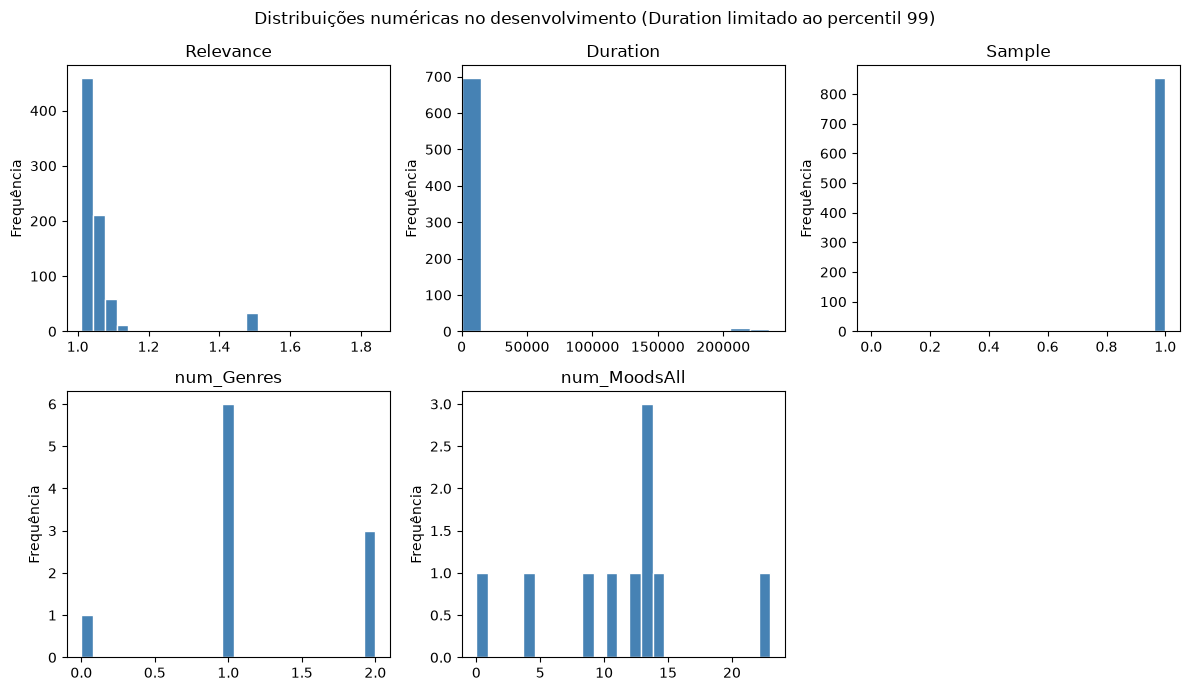

In [44]:
numeric = development.select_dtypes(include="number").columns.tolist()
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, column in zip(axes.flat, numeric):
    values = development[column].dropna()
    ax.hist(values, bins=25, color="steelblue", edgecolor="white")
    ax.set(title=column, ylabel="Frequência")
    if column == "Duration" and len(values):
        ax.set_xlim(min(0, values.min()), values.quantile(0.99))
for ax in axes.flat[len(numeric):]:
    ax.set_visible(False)
fig.suptitle("Distribuições numéricas no desenvolvimento (Duration limitado ao percentil 99)")
fig.tight_layout()
plt.show()

**Interpretação:** os histogramas mostram como se distribuem os valores numéricos. No gráfico de `Duration`, o eixo está limitado ao percentil 99 para facilitar a leitura; os valores acima desse limite continuam nos dados e serão investigados.

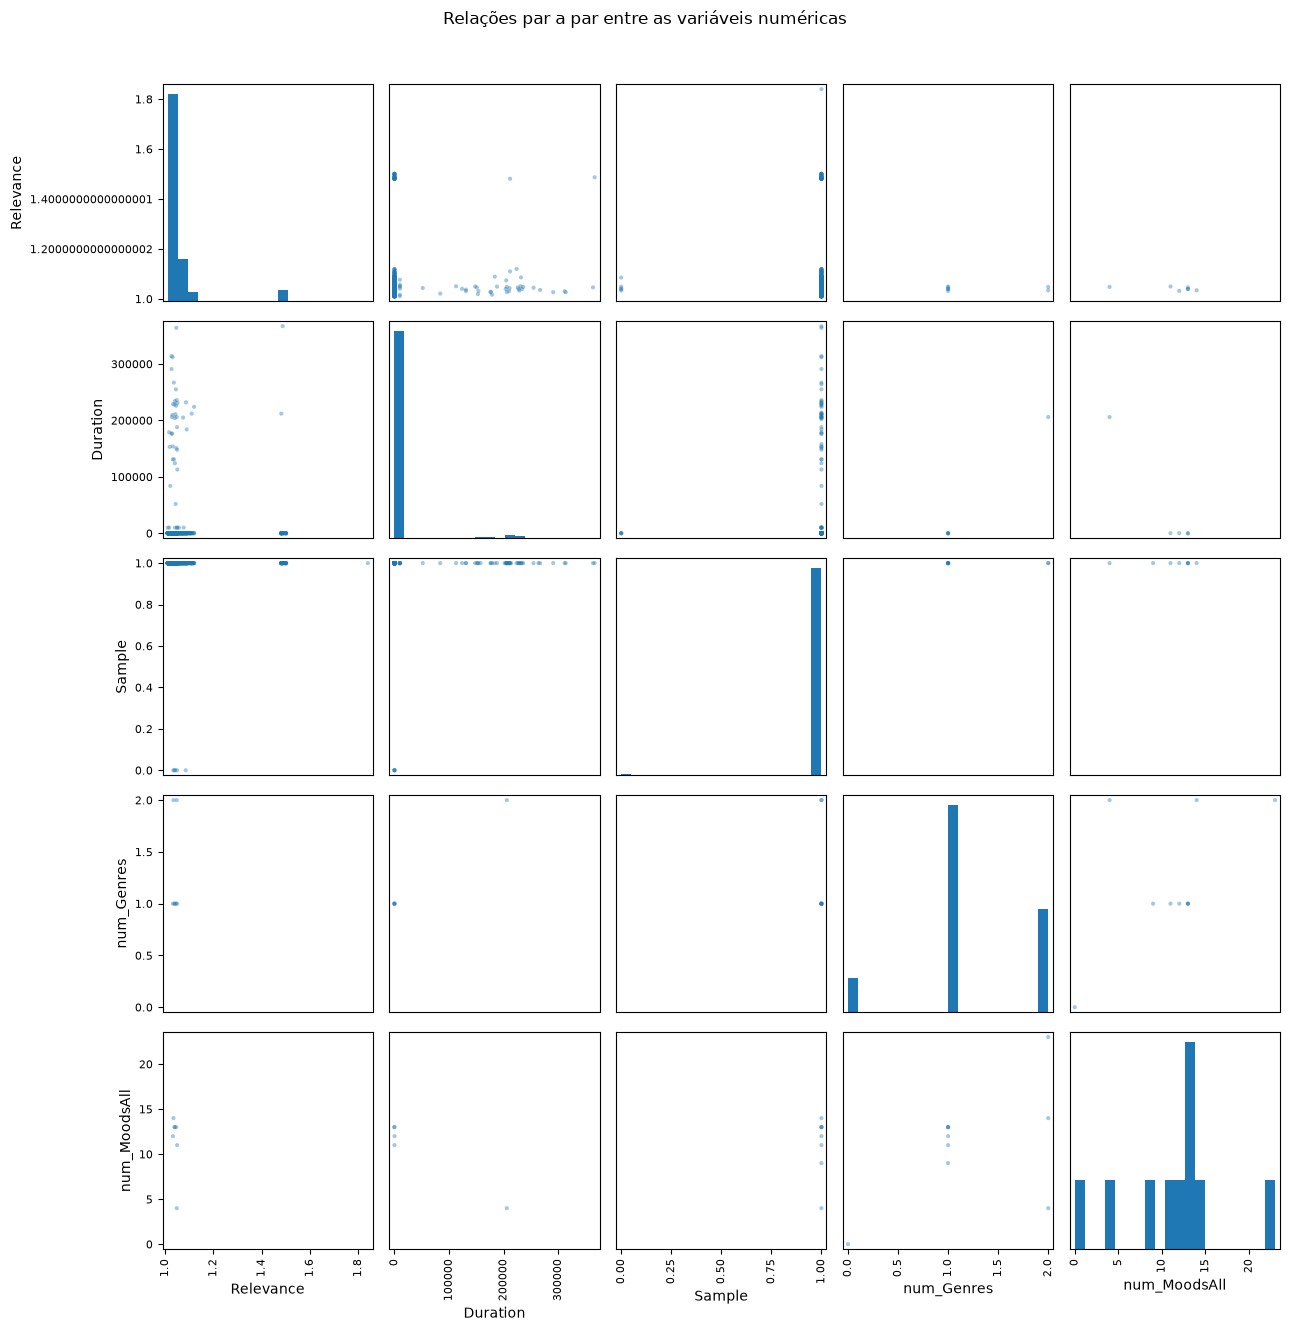

In [45]:
numeric = development.select_dtypes(include="number").columns.tolist()
fig = pd.plotting.scatter_matrix(
    development[numeric],
    figsize=(13, 13),
    diagonal="hist",
    alpha=0.4,
    marker=".",
    hist_kwds={"bins": 20},
)
plt.suptitle("Relações par a par entre as variáveis numéricas", y=1.02)
plt.tight_layout()
plt.show()

**Interpretação:** cada painel compara duas variáveis numéricas e a diagonal mostra a distribuição de cada uma. Os valores em falta não foram preenchidos. As colunas quase vazias e os valores extremos dificultam a leitura, por isso estas relações devem ser vistas como uma primeira exploração.

### 3.3–3.4 Relação entre cada coluna e o quadrante

Para comparar as colunas, dividimos o conjunto de desenvolvimento em cinco partes e, em cada ronda, prevemos a classe mais frequente para cada valor (ou intervalo numérico). Usamos macro-F1, que dá o mesmo peso às quatro classes, e comparamos o resultado com uma previsão de referência baseada na classe mais frequente. As linhas da mesma música ficam sempre na mesma parte. É uma comparação inicial de cada coluna, não substitui o modelo k-NN do projeto.

In [46]:
classes = ["Q1", "Q2", "Q3", "Q4"]
songs = development[["Audio_Song", "Quadrant"]].drop_duplicates()
rng = np.random.default_rng(42)
fold_map = {}
for label in classes:
    ids = songs.loc[songs["Quadrant"] == label, "Audio_Song"].to_numpy().copy()
    rng.shuffle(ids)
    fold_map.update({song: i % 5 for i, song in enumerate(ids)})
fold = development["Audio_Song"].map(fold_map)

def keys_for(train, valid):
    x_train = pd.to_numeric(train, errors="coerce")
    x_valid = pd.to_numeric(valid, errors="coerce")
    if train.notna().sum() and x_train.notna().sum() / train.notna().sum() >= 0.95:
        edges = np.r_[-np.inf, x_train.dropna().quantile([.2, .4, .6, .8]).unique(), np.inf]
        a = pd.cut(x_train, edges, include_lowest=True).astype(str).where(x_train.notna(), "[em falta]")
        b = pd.cut(x_valid, edges, include_lowest=True).astype(str).where(x_valid.notna(), "[em falta]")
    else:
        a, b = train.fillna("[em falta]").astype(str), valid.fillna("[em falta]").astype(str)
    return a, b

def macro_f1(actual, predicted):
    values = []
    for label in classes:
        tp = ((actual == label) & (predicted == label)).sum()
        fp = ((actual != label) & (predicted == label)).sum()
        fn = ((actual == label) & (predicted != label)).sum()
        values.append(2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0)
    return np.mean(values)

features = joined.drop(columns=["Quadrant", "_merge"]).columns
results = []
for feature in features:
    prediction = pd.Series(index=joined.index, dtype="object")
    baseline = pd.Series(index=joined.index, dtype="object")
    for part in range(5):
        valid = fold == part
        train = ~valid
        train_key, valid_key = keys_for(joined.loc[train, feature], joined.loc[valid, feature])
        labels = joined.loc[train, "Quadrant"]
        majority = labels.value_counts().idxmax()
        lookup = pd.DataFrame({"key": train_key, "label": labels}).groupby("key")["label"].agg(lambda x: x.value_counts().idxmax())
        prediction.loc[valid] = valid_key.map(lookup).fillna(majority)
        baseline.loc[valid] = majority
    actual = joined["Quadrant"]
    results.append({
        "coluna": feature,
        "accuracy": (prediction == actual).mean(),
        "macro-F1": macro_f1(actual, prediction),
        "macro-F1 referência": macro_f1(actual, baseline),
    })

results = pd.DataFrame(results).sort_values("macro-F1", ascending=False).reset_index(drop=True)
display(results.round(3))
suspects = results[results["coluna"].isin(["Arousal", "Valence"])]
reference = results["macro-F1 referência"].mean()
print(f"Suspeitas Arousal/Valence acima da referência: {(suspects['macro-F1'] > reference).sum()} de {len(suspects)}.")

,coluna,accuracy,macro-F1,macro-F1 referência
0,Genres,0.591,0.497,0.143
1,Styles,0.578,0.495,0.143
2,Arousal,0.721,0.494,0.143
3,Artist,0.535,0.447,0.143
4,Valence,0.723,0.407,0.143
5,Moods,0.533,0.396,0.143
6,Themes,0.541,0.388,0.143
7,Year,0.484,0.381,0.143
8,MoodsAll,0.488,0.337,0.143
9,StyleWeights,0.464,0.336,0.143


Suspeitas Arousal/Valence acima da referência: 2 de 2.


**Interpretação:** as colunas no topo têm maior associação com o quadrante nesta comparação. `Arousal` e `Valence` não devem entrar no modelo, porque são usadas para definir a própria classe. Nas outras colunas, uma associação elevada não prova, por si só, fuga de informação nem uma relação de causa.

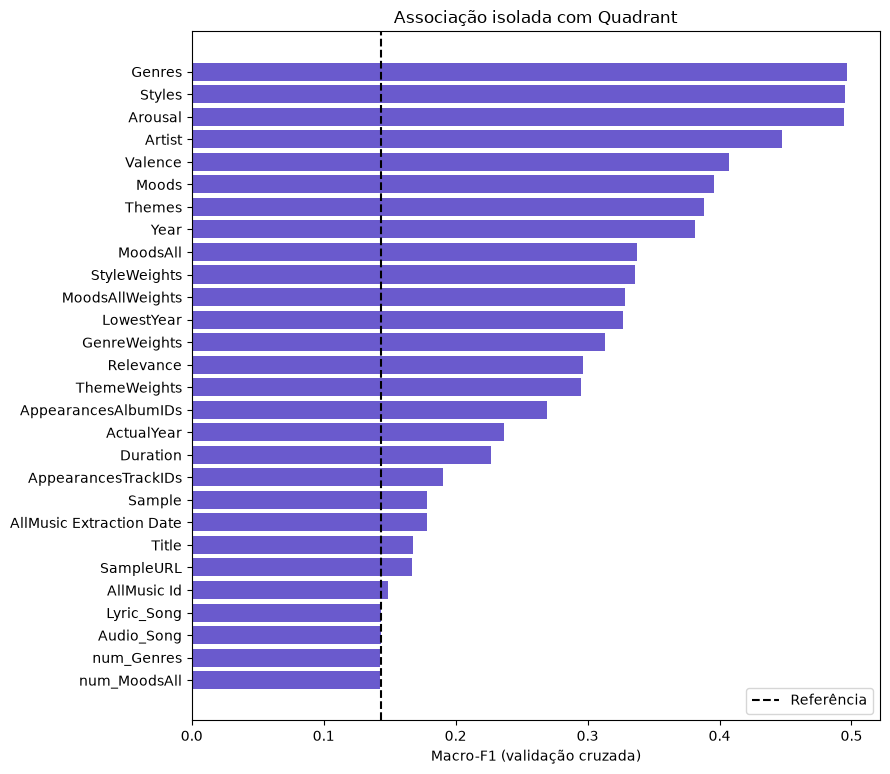

In [47]:
plot = results.sort_values("macro-F1")
fig, ax = plt.subplots(figsize=(9, max(6, len(plot) * 0.28)))
ax.barh(plot["coluna"], plot["macro-F1"], color="slateblue")
ax.axvline(reference, color="black", linestyle="--", label="Referência")
ax.set(xlabel="Macro-F1 (validação cruzada)", title="Associação isolada com Quadrant")
ax.legend()
fig.tight_layout()
plt.show()

**Interpretação:** o gráfico ordena as colunas pela pontuação macro-F1 e mostra a linha de referência. Os valores exatos estão na tabela anterior. As variáveis que podem revelar a resposta foram identificadas antes desta comparação.

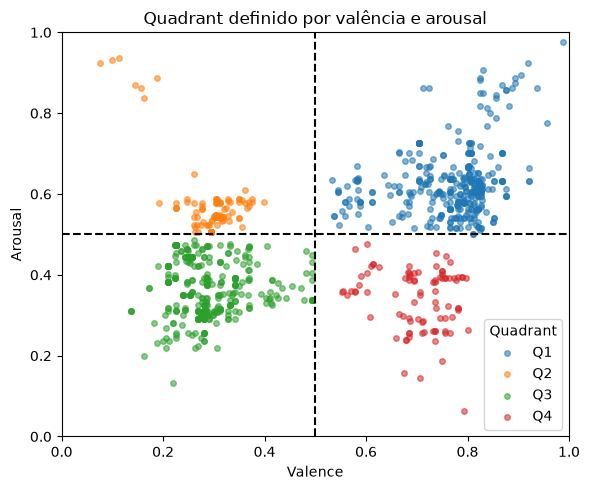

In [48]:
fig, ax = plt.subplots(figsize=(6, 5))
for label, group in joined.groupby("Quadrant"):
    ax.scatter(group["Valence"], group["Arousal"], s=16, alpha=.55, label=label)
ax.axvline(.5, color="black", linestyle="--")
ax.axhline(.5, color="black", linestyle="--")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Valence", ylabel="Arousal", title="Quadrant definido por valência e arousal")
ax.legend(title="Quadrant")
fig.tight_layout()
plt.show()

**Interpretação:** as linhas tracejadas mostram os limites de 0,5 usados para formar os quadrantes. Como `Valence` e `Arousal` determinam a classe, não devem ser usadas para a prever.

### 3.5 Artistas que aparecem no desenvolvimento e no teste

In [49]:
development_artists = set(development["Artist"].dropna())
test_songs = test.drop_duplicates("Audio_Song")
shared = test_songs["Artist"].isin(development_artists)
print(f"Músicas de teste com artista (mesma grafia) no desenvolvimento: {shared.sum()} de {len(test_songs)}.")
print(f"Artistas distintos partilhados: {test_songs.loc[shared, 'Artist'].nunique()}.")

Músicas de teste com artista (mesma grafia) no desenvolvimento: 200 de 409.
Artistas distintos partilhados: 104.


**Interpretação:** esta contagem compara os nomes dos artistas tal como estão escritos; diferenças de grafia podem esconder correspondências. É uma verificação de possível sobreposição entre desenvolvimento e teste, pedida no enunciado. Não usa os rótulos do teste nem mede o desempenho de um modelo.

## Síntese das perguntas 2 e 3

### O que foi analisado

Começámos por separar o teste e trabalhar apenas com o desenvolvimento. Consultámos o significado e o tipo das colunas, contámos valores em falta e distintos, cruzámos `metadata.csv` com `av_values.csv` e verificámos os ficheiros de áudio, letras e capas. Depois, explorámos as distribuições e os valores numéricos, observámos as relações entre variáveis e comparamos a associação de cada coluna ao quadrante através de uma validação com base na classe e agrupada por música. Nesta fase, os dados foram observados, não limpos.

### O que os resultados mostram

- **Estrutura e classes:** o desenvolvimento tem 932 linhas referentes a 914 músicas únicas; 18 linhas repetem os mesmos IDs de áudio e letra. As classes não aparecem por igual: há 374 registos Q1, 112 Q2, 356 Q3 e 90 Q4. Assim, Q1 e Q3 são as mais frequentes, enquanto Q2 e Q4 tEm menos exemplos.
- **Cruzamento das fontes:** os 914 pares únicos de IDs encontram correspondência em `av_values.csv`; não ficaram linhas sem correspondência. Há áudio e letra para as 914 músicas. Das capas, existem 825 e faltam 89. Nenhum dos ficheiros encontrados está guardado numa pasta de quadrante diferente da indicada nos metadados.
- **Qualidade dos metadados:** nenhuma coluna é constante, mas `num_Genres` e `num_MoodsAll` têm 98,9% de valores em falta e são pouco informativas tal como estão. Também faltam valores em `LowestYear` (34,5%), `ActualYear` (22,7%), `Duration` (20,4%) e `Relevance` (17,2%). Os gráficos e os resumos numéricos confirmam casos a investigar: `Duration` vai de -1 a 367 000, apesar de representar segundos, e `ActualYear` inclui 0 e 9999. Estes valores não foram corrigidos nesta etapa.
- **Relação com o quadrante:** a comparação individual deu os maiores macro-F1 a `Genres` (0,497), `Styles` (0,495) e `Arousal` (0,494); `Valence` obteve 0,407. Como referência, prever sempre a classe mais frequente teve macro-F1 de 0,143. Estes valores servem para uma primeira comparação, não medem o desempenho de um modelo final. Em particular, `Arousal` e `Valence` não podem ser usadas como preditores: o quadrante é definido a partir delas, com limites de 0,5. O gráfico dos quadrantes torna essa relação visível.
- **Partilha de artistas:** 200 das 409 músicas de teste têm um artista com a mesma grafia no desenvolvimento (104 artistas distintos). Portanto, o teste inclui artistas já vistos e artistas não vistos; uma avaliação destinada a medir generalização para artistas novos deve manter cada artista num único grupo.

### Conclusão

O cruzamento confirma que os metadados têm correspondência completa com `av_values.csv` e que áudio e letras estão disponíveis para todas as músicas de desenvolvimento; as capas são opcionais e estão em falta em cerca de uma em cada dez músicas. A exploração revela desequilíbrio entre quadrantes, ausência elevada em algumas colunas e valores suspeitos em duração e ano, que ficam para a limpeza do exercício 4. Para a modelação, excluímos a classe, `Arousal`, `Valence` e qualquer caminho de ficheiro que exponha o quadrante. As pontuações por coluna são apenas indícios exploratórios; não permitem concluir causalidade nem escolher, por si só, as variáveis de um modelo.

# 4. Limpeza dos dados

Nesta secção procuramos duplicados, analisamos os valores em falta e identificamos erros e possíveis outliers. Só depois aplicamos regras justificadas. O conjunto de teste continua separado: as regras e estatísticas são definidas no desenvolvimento e aplicadas ao teste sem voltar a ajustá-las.

## 4.1 Duplicados

Comparamos os IDs, artista e título, o conteúdo dos ficheiros de áudio e das letras. Um nome igual é apenas uma pista; ficheiros idênticos dão evidência mais forte de que se trata da mesma gravação.

In [50]:
import hashlib

def media_index(folder, suffix):
    return {p.stem: p for p in (media_dir / folder).rglob(f"*{suffix}") if p.is_file() and not p.name.startswith("._")}

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

audio_paths = media_index("audio", ".mp3")
lyric_paths = media_index("lyrics", ".txt")
unique_songs = metadata.drop_duplicates("Audio_Song").copy()
unique_songs["split"] = np.where(unique_songs["Audio_Song"].isin(test_ids), "teste", "desenvolvimento")
unique_songs["audio_hash"] = unique_songs["Audio_Song"].map(lambda song: sha256(audio_paths[song]) if song in audio_paths else None)
unique_songs["lyric_hash"] = unique_songs["Lyric_Song"].map(lambda song: sha256(lyric_paths[song]) if song in lyric_paths else None)

audio_groups = unique_songs.dropna(subset="audio_hash").groupby("audio_hash")
lyric_groups = unique_songs.dropna(subset="lyric_hash").groupby("lyric_hash")
same_audio = audio_groups.filter(lambda group: group["Audio_Song"].nunique() > 1)
same_lyrics = lyric_groups.filter(lambda group: group["Lyric_Song"].nunique() > 1)
same_track_id = metadata.groupby("AllMusic Id").agg(
    musicas=("Audio_Song", "nunique"), artistas=("Artist", "nunique"), titulos=("Title", "nunique")
).query("musicas > 1 or artistas > 1 or titulos > 1")
cross_split_audio = sum(group["split"].nunique() > 1 for _, group in audio_groups)
artist_variants = metadata.groupby("AllMusic Id")["Artist"].nunique().gt(1).sum()
title_variants = metadata.groupby("AllMusic Id")["Title"].nunique().gt(1).sum()

duplicate_evidence = pd.DataFrame([
    {"evidência": "Linhas exatamente repetidas no desenvolvimento", "grupos/registos": int(development.duplicated().sum())},
    {"evidência": "IDs AllMusic ligados a mais de uma música", "grupos/registos": int((metadata.groupby("AllMusic Id")["Audio_Song"].nunique() > 1).sum())},
    {"evidência": "Gravações de áudio idênticas com IDs diferentes", "grupos/registos": int(same_audio["audio_hash"].nunique())},
    {"evidência": "Letras idênticas com IDs diferentes", "grupos/registos": int(same_lyrics["lyric_hash"].nunique())},
    {"evidência": "IDs AllMusic com grafias diferentes de artista", "grupos/registos": int(artist_variants)},
    {"evidência": "IDs AllMusic com títulos diferentes", "grupos/registos": int(title_variants)},
    {"evidência": "Gravações de áudio idênticas nos dois lados da divisão", "grupos/registos": int(cross_split_audio)},
    ])
display(duplicate_evidence)
display(same_audio[["Audio_Song", "Lyric_Song", "Artist", "Title", "split"]].head(12))

,evidência,grupos/registos
0,Linhas exatamente repetidas no desenvolvimento,18
1,IDs AllMusic ligados a mais de uma música,1
2,Gravações de áudio idênticas com IDs diferentes,2
3,Letras idênticas com IDs diferentes,3
4,IDs AllMusic com grafias diferentes de artista,1
5,IDs AllMusic com títulos diferentes,1
6,Gravações de áudio idênticas nos dois lados da...,1


,Audio_Song,Lyric_Song,Artist,Title,split
165,MT0003503243,MT0003503243,Godsmack,I F****** Hate You,desenvolvimento
220,MT0011933875,MT0011933875,Luther Vandross,Never Too Much,desenvolvimento
931,A114-120,L004-120,Luther Vandross,Never Too Much - Remastered,desenvolvimento
1058,A028,L078,Godsmack,I Fucking Hate You,teste


**Interpretação:** linhas exatamente repetidas podem ser removidas sem perder informação. Um ID AllMusic partilhado ou ficheiros idênticos pedem uma verificação mais cuidada; não juntamos automaticamente gravações diferentes só porque artista e título coincidem. Se a mesma gravação estiver nos dois lados, removê-la do desenvolvimento evita que a validação beneficie de uma cópia presente no teste, sem alterar o teste. Para validação cruzada, as músicas do mesmo artista devem ficar no mesmo grupo.

## 4.2 Valores em falta

A percentagem em falta, por si só, não explica a causa. Comparamos os padrões com o quadrante e com o número de músicas por artista; estas associações são indícios, não provam o mecanismo.

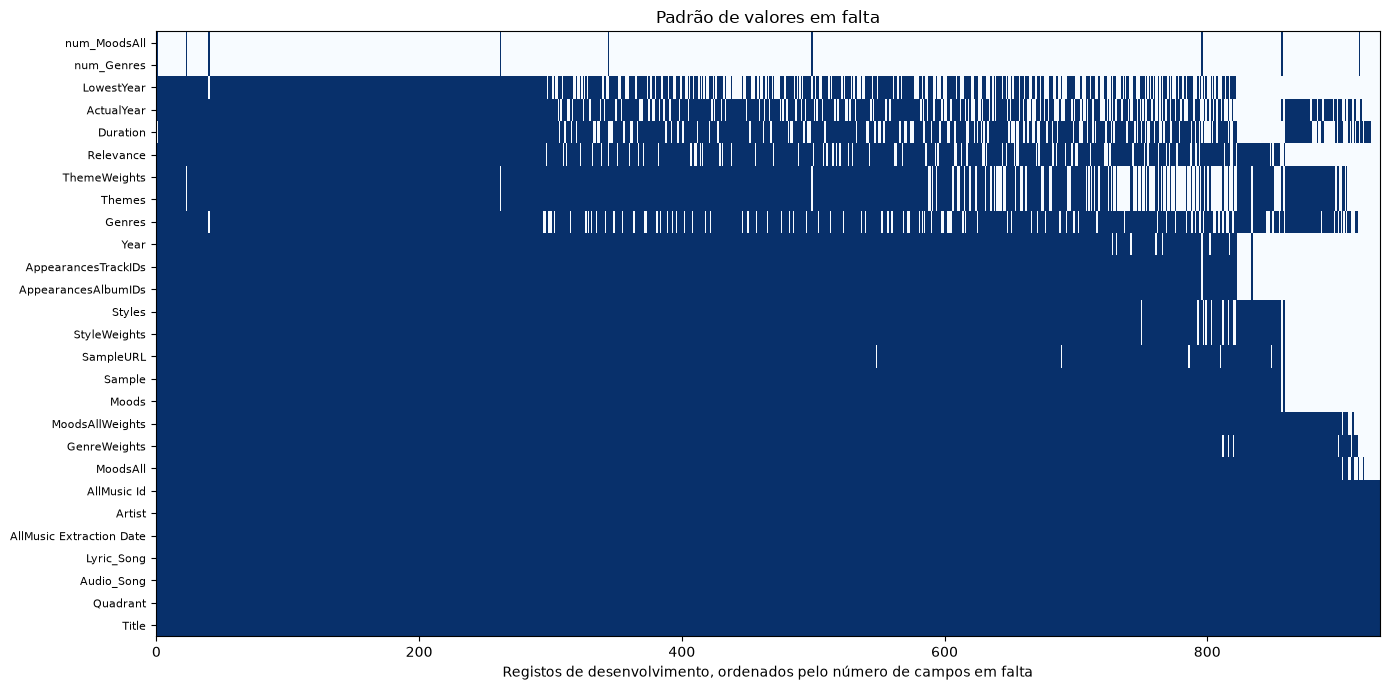

,coluna,em falta (%),Q1 (%),Q2 (%),Q3 (%),Q4 (%),p (quadrante),p (tamanho artista)
26,num_MoodsAll,98.9,97.9,100.0,99.4,100.0,0.0696,0.9393
25,num_Genres,98.9,97.9,100.0,99.4,100.0,0.0696,0.9393
9,LowestYear,34.5,40.6,21.4,31.5,37.8,0.0009,0.2412
24,ActualYear,22.7,22.5,21.4,22.8,25.6,0.9117,0.0241
10,Duration,20.4,19.3,10.7,22.5,28.9,0.0084,0.7176
7,Relevance,17.2,16.8,15.2,18.5,15.6,0.8074,0.5616
17,ThemeWeights,16.2,17.6,32.1,8.7,20.0,0.0000,0.0134
16,Themes,16.2,17.6,32.1,8.7,20.0,0.0000,0.0134
14,Genres,13.5,7.2,9.8,18.5,24.4,0.0000,0.1863
8,Year,12.4,11.5,8.9,13.5,16.7,0.3335,0.7014


In [56]:
from scipy.stats import chi2_contingency

missing_pct = development.isna().mean().mul(100).sort_values(ascending=False)
artist_sizes = development.groupby("Artist")["Audio_Song"].transform("nunique")
artist_size_group = pd.qcut(artist_sizes.rank(method="first"), 4, labels=False)
missing_patterns = development.isna().loc[:, missing_pct.index]
row_order = missing_patterns.sum(axis=1).sort_values(kind="stable").index

fig, ax = plt.subplots(figsize=(14, 7))
ax.imshow(missing_patterns.loc[row_order].T, aspect="auto", interpolation="nearest", cmap="Blues_r", vmin=0, vmax=1)
ax.set(yticks=np.arange(len(missing_pct)), yticklabels=missing_pct.index, xlabel="Registos de desenvolvimento, ordenados pelo número de campos em falta", title="Padrão de valores em falta")
ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
plt.show()

missingness_rows = []
for column in development.columns:
    absent = development[column].isna().astype(int)
    row = {"coluna": column, "em falta (%)": round(100 * absent.mean(), 1)}
    for quadrant in ["Q1", "Q2", "Q3", "Q4"]:
        row[f"{quadrant} (%)"] = round(100 * absent[development["Quadrant"].eq(quadrant)].mean(), 1)
    q_table = pd.crosstab(development["Quadrant"], absent)
    row["p (quadrante)"] = chi2_contingency(q_table).pvalue if q_table.shape == (4, 2) else np.nan
    artist_table = pd.crosstab(artist_size_group, absent)
    row["p (tamanho artista)"] = chi2_contingency(artist_table).pvalue if artist_table.shape == (4, 2) else np.nan
    missingness_rows.append(row)
missingness_summary = pd.DataFrame(missingness_rows).sort_values("em falta (%)", ascending=False)
display(missingness_summary.round(4))

**Interpretação:** o mapa mostra se os valores em falta aparecem isolados ou em blocos. As percentagens por quadrante e os testes indicam se a ausência está associada a informação observada. Um valor-p baixo sugere associação, mas não identifica sozinho a causa; a ausência dependente do próprio valor em falta não pode ser confirmada apenas com estes dados.

### 4.2.3 Comparação de imputações

Usamos `Relevance` para comparar métodos num valor observado e depois ocultado aleatoriamente. É uma verificação controlada, não garante o mesmo resultado para colunas cuja ausência não seja aleatória.

In [52]:
imputation_data = development.drop_duplicates("Audio_Song")[["Audio_Song", "Artist", "Relevance"]].copy()
imputation_data["Relevance"] = pd.to_numeric(imputation_data["Relevance"], errors="coerce")
observed = imputation_data.dropna(subset="Relevance")
rng = np.random.default_rng(42)
permutation = rng.permutation(len(observed))
holdout = observed.iloc[permutation[:max(1, int(0.2 * len(observed)))]]
training = observed.iloc[permutation[max(1, int(0.2 * len(observed))):]]
global_median = training["Relevance"].median()
artist_medians = training.groupby("Artist")["Relevance"].median()
predictions = {
    "mediana global": pd.Series(global_median, index=holdout.index),
    "média global": pd.Series(training["Relevance"].mean(), index=holdout.index),
    "mediana do artista (fallback global)": holdout["Artist"].map(artist_medians).fillna(global_median),
}
imputation_scores = pd.DataFrame([
    {"método": name, "MAE": (pred - holdout["Relevance"]).abs().mean(), "RMSE": np.sqrt(((pred - holdout["Relevance"]) ** 2).mean()), "viés": (pred - holdout["Relevance"]).mean()}
    for name, pred in predictions.items()
]).sort_values("MAE")
display(imputation_scores.round(4))

,método,MAE,RMSE,viés
0,mediana global,0.0189,0.0547,-0.0074
2,mediana do artista (fallback global),0.0250,0.0713,0.0033
1,média global,0.0354,0.0576,0.0196


**Interpretação:** a tabela compara o erro nos valores que escondemos, sem os usar para calcular as imputações. Como `Duration` pode faltar precisamente nas faixas mais longas, preencher todas as ausências com uma mediana pode subestimar a duração. Além disso, preencher `Genres` com base em `Quadrant` usaria a própria resposta e criaria fuga de informação. Por isso, a limpeza preserva indicadores de ausência e evita esta imputação por classe.

## 4.3 Erros e inconsistências

Procuramos valores impossíveis isoladamente e pares de valores que se contradizem. As regras abaixo usam o dicionário e a coerência entre colunas.

In [53]:
duration_raw = pd.to_numeric(development["Duration"], errors="coerce")
year_raw = pd.to_numeric(development["ActualYear"], errors="coerce")
duration_units = pd.DataFrame([
    {"regra": "Duração não positiva", "registos": int(duration_raw.le(0).sum())},
    {"regra": "Sentinela 9999 em Duration", "registos": int(duration_raw.eq(9999).sum())},
    {"regra": "Duração acima de 10 000 (prováveis milissegundos)", "registos": int(duration_raw.gt(10000).sum())},
    {"regra": "Duração positiva abaixo de 10 (possíveis minutos)", "registos": int(duration_raw.between(0, 10, inclusive="neither").sum())},
    {"regra": "ActualYear igual a zero", "registos": int(year_raw.eq(0).sum())},
    {"regra": "ActualYear no futuro", "registos": int(year_raw.gt(pd.Timestamp.now().year).sum())},
])
display(duration_units)

def extract_year(values):
    return pd.to_numeric(values.astype("string").str.extract(r"(\d{4})", expand=False), errors="coerce")

actual_year = pd.to_numeric(development["ActualYear"], errors="coerce")
lowest_year = extract_year(development["LowestYear"])
year_conflicts = development.loc[actual_year.lt(lowest_year), ["Audio_Song", "Artist", "Title", "ActualYear", "LowestYear"]].copy()
display(year_conflicts.head(20))

weight_pairs = [("MoodsAll", "MoodsAllWeights"), ("Genres", "GenreWeights"), ("Themes", "ThemeWeights"), ("Styles", "StyleWeights")]
weight_checks = []
for tags, weights in weight_pairs:
    tag_count = development[tags].fillna("").astype(str).map(lambda value: sum(bool(item.strip()) for item in value.split(",")))
    weight_count = development[weights].fillna("").astype(str).map(lambda value: sum(bool(item.strip()) for item in value.split(",")))
    mismatch = tag_count.ne(weight_count) & (tag_count.gt(0) | weight_count.gt(0))
    weight_checks.append({"etiquetas": tags, "pesos": weights, "pares com contagens diferentes": int(mismatch.sum())})
display(pd.DataFrame(weight_checks))

,regra,registos
0,Duração não positiva,82
1,Sentinela 9999 em Duration,7
2,Duração acima de 10 000 (prováveis milissegundos),46
3,Duração positiva abaixo de 10 (possíveis minutos),18
4,ActualYear igual a zero,7
5,ActualYear no futuro,19


,Audio_Song,Artist,Title,ActualYear,LowestYear
78,MT0009321428,"Cure, The",This Is a Lie,1976,21/05/1996
91,MT0011950450,Neil Diamond,Hark! The Herald Angels Sing,1978,22/09/1992
112,MT0007438571,Liz Phair,Divorce Song,1987,22/06/1993
115,MT0005740567,Inner Circle,You've Lost That Lovin' Feelin',1988,21/05/2002
122,MT0003362617,GARTH BROOKS,Which One of Them,1979,10/09/1991
126,MT0034410340,John Lee Hooker,No Rollin' Blues,1900,20/02/1996
145,MT0014798420,Bubba Sparxxx,Ain't Life Grand,2000,04/04/2006
155,MT0030289937,Louis Armstrong,Billie's Blues,1987,09/10/2001
185,MT0001542457,AC/DC,Show Down in Flames,1900,18/11/1997
195,MT0016976154,Patsy Cline,Yes' I Understand,1900,25/06/2007


,etiquetas,pesos,pares com contagens diferentes
0,MoodsAll,MoodsAllWeights,11
1,Genres,GenreWeights,112
2,Themes,ThemeWeights,6
3,Styles,StyleWeights,8


**Interpretação:** durações não positivas e o valor `9999` não representam uma duração válida; valores muito grandes podem estar em milissegundos e valores pequenos podem estar em minutos. Um `ActualYear` igual a zero ou posterior ao ano atual é inválido. Quando `ActualYear` antecede `LowestYear`, a contradição envolve as duas colunas. Se o número de pesos não corresponder ao de etiquetas, não é seguro associar cada peso a uma etiqueta.

## 4.4 Outliers

Comparamos três regras univariadas e duas abordagens multivariadas. Um registo assinalado é um caso a investigar, não um erro automático.

In [54]:
from sklearn.cluster import DBSCAN, KMeans
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA

numeric_candidates = ["Duration", "Relevance", "ActualYear", "Sample"]
outlier_data = development[numeric_candidates].apply(pd.to_numeric, errors="coerce").copy()
outlier_data.loc[outlier_data["Duration"].le(0) | outlier_data["Duration"].eq(9999), "Duration"] = np.nan
outlier_data.loc[outlier_data["Duration"].gt(10000), "Duration"] /= 1000
minute_values = outlier_data["Duration"].between(0, 10, inclusive="neither")
outlier_data.loc[minute_values, "Duration"] *= 60
outlier_data.loc[outlier_data["ActualYear"].le(0) | outlier_data["ActualYear"].gt(pd.Timestamp.now().year), "ActualYear"] = np.nan

univariate_flags = []
for column in numeric_candidates:
    values = outlier_data[column].dropna()
    if values.nunique() < 2:
        continue
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    median = values.median()
    mad = (values - median).abs().median()
    z_flag = (values - values.mean()).abs().div(values.std(ddof=0)).gt(3)
    mad_score = (0.6745 * (values - median) / mad).abs() if mad else pd.Series(0, index=values.index)
    iqr_flag = values.lt(q1 - 1.5 * iqr) | values.gt(q3 + 1.5 * iqr)
    univariate_flags.append({"coluna": column, "z-score > 3": int(z_flag.sum()), "MAD modificado > 3.5": int(mad_score.gt(3.5).sum()), "regra IQR": int(iqr_flag.sum())})
display(pd.DataFrame(univariate_flags))

cluster_source = outlier_data[["Duration", "Relevance", "ActualYear"]]
X_cluster = RobustScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(cluster_source))
neighbor_distances = NearestNeighbors(n_neighbors=6).fit(X_cluster).kneighbors(X_cluster)[0][:, -1]
sorted_distances = np.sort(neighbor_distances)
line = np.linspace(sorted_distances[0], sorted_distances[-1], len(sorted_distances))
knee = int(np.argmax(sorted_distances - line))
eps_choice = float(sorted_distances[knee])

kmeans_results = []
kmeans_models = {}
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X_cluster)
    kmeans_models[k] = model
    kmeans_results.append({"k": k, "inércia": model.inertia_, "silhouette": silhouette_score(X_cluster, model.labels_)})
kmeans_scores = pd.DataFrame(kmeans_results)
best_k = int(kmeans_scores.loc[kmeans_scores["silhouette"].idxmax(), "k"])
dbscan_labels = DBSCAN(eps=eps_choice, min_samples=6).fit_predict(X_cluster)
kmeans_labels = kmeans_models[best_k].labels_
display(kmeans_scores.round(3))
print(f"DBSCAN: min_samples=6; eps={eps_choice:.3f} (joelho da curva das distâncias aos 5 vizinhos); ruído={int((dbscan_labels == -1).sum())} registos.")

projection = PCA(n_components=2, random_state=42).fit_transform(X_cluster)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(projection[:, 0], projection[:, 1], c=kmeans_labels, cmap="tab10", s=18, alpha=.65)
axes[0].set(title=f"K-means (k={best_k})", xlabel="Componente principal 1", ylabel="Componente principal 2")
axes[1].scatter(projection[:, 0], projection[:, 1], c=np.where(dbscan_labels == -1, 1, 0), cmap="coolwarm", s=18, alpha=.65)
axes[1].set(title="DBSCAN (ruído destacado)", xlabel="Componente principal 1", ylabel="Componente principal 2")
fig.tight_layout()
plt.show()

nn_model = NearestNeighbors(n_neighbors=2).fit(X_cluster)
nearest_distance = nn_model.kneighbors(X_cluster)[0][:, 1]
nn_limit = np.quantile(nearest_distance, .99)
outlier_records = development.loc[(dbscan_labels == -1) | (nearest_distance > nn_limit), ["Audio_Song", "Quadrant", "Artist", "Title"]].copy()
outlier_records["distância ao vizinho mais próximo"] = nearest_distance[(dbscan_labels == -1) | (nearest_distance > nn_limit)]
outlier_records["DBSCAN ruído"] = dbscan_labels[(dbscan_labels == -1) | (nearest_distance > nn_limit)] == -1
display(outlier_records.sort_values("distância ao vizinho mais próximo", ascending=False).head(20))

,coluna,z-score > 3,MAD modificado > 3.5,regra IQR
0,Duration,7,11,29
1,Relevance,34,71,97
2,ActualYear,10,14,11
3,Sample,5,0,5


InvalidParameterError: The 'eps' parameter of DBSCAN must be a float in the range (0.0, inf). Got 0.0 instead.

**Interpretação:** o z-score é sensível a distribuições assimétricas; o MAD e a regra IQR são mais robustos, mas também podem assinalar valores legítimos. K-means agrupa todos os registos, enquanto DBSCAN pode marcar pontos isolados como ruído. Os parâmetros estão ligados às curvas apresentadas e as duas dimensões do gráfico são uma projeção PCA, não os dados usados diretamente pelo agrupamento. Só corrigimos valores impossíveis com uma regra clara; os restantes ficam assinalados para revisão.

## 4.5 Ficheiros de media

Verificamos dimensões e repetição das capas e calculamos estatísticas simples do áudio de desenvolvimento. O teste não entra nesta análise.

In [ ]:
from PIL import Image

cover_paths = media_index("album_covers", ".jpg")
dev_songs = development.drop_duplicates("Audio_Song")
cover_rows = []
invalid_covers = []
for song in dev_songs["Audio_Song"]:
    path = cover_paths.get(song)
    if path is None:
        continue
    try:
        with Image.open(path) as image:
            width, height = image.size
            image.verify()
        cover_rows.append({"Audio_Song": song, "largura": width, "altura": height, "hash": sha256(path)})
    except (OSError, ValueError) as error:
        invalid_covers.append({"Audio_Song": song, "erro": str(error)})
cover_dimensions = pd.DataFrame(cover_rows)
print(f"Capas em falta: {dev_songs['Audio_Song'].isin(cover_paths).eq(False).sum()} | capas ilegíveis: {len(invalid_covers)} | capas válidas: {len(cover_dimensions)}")
print(f"Ficheiros de capa duplicados por conteúdo: {int(cover_dimensions['hash'].duplicated().sum()) if len(cover_dimensions) else 0}")
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(cover_dimensions["largura"], cover_dimensions["altura"], alpha=.65, color="teal")
ax.set(xlabel="Largura (píxeis)", ylabel="Altura (píxeis)", title="Dimensões das capas do desenvolvimento")
fig.tight_layout()
plt.show()

**Interpretação:** a verificação distingue capas em falta, ficheiros ilegíveis e imagens repetidas. A ausência de capa é permitida pelo dicionário, por isso não justifica remover uma música.

In [ ]:
import subprocess
import imageio_ffmpeg

sample_rate = 11025
ffmpeg = imageio_ffmpeg.get_ffmpeg_exe()
audio_rows = []
example_signal = None
example_song = None
for song in dev_songs["Audio_Song"]:
    path = audio_paths.get(song)
    if path is None:
        raise FileNotFoundError(f"Ficheiro de áudio em falta para {song}.")
    decoded = subprocess.run(
        [ffmpeg, "-v", "error", "-i", str(path), "-ac", "1", "-ar", str(sample_rate), "-f", "f32le", "pipe:1"],
        check=True, stdout=subprocess.PIPE, stderr=subprocess.PIPE,
    )
    signal = np.frombuffer(decoded.stdout, dtype="<f4")
    if not len(signal):
        raise ValueError(f"O ficheiro de áudio {song} não produziu amostras.")
    audio_rows.append({
        "Audio_Song": song,
        "duração (s)": len(signal) / sample_rate,
        "energia média": float(np.mean(signal ** 2)),
        "RMS": float(np.sqrt(np.mean(signal ** 2))),
        "amplitude máxima": float(np.max(np.abs(signal))),
        "taxa de cruzamentos por zero": float(np.mean(np.signbit(signal[1:]) != np.signbit(signal[:-1]))),
    })
    if example_signal is None:
        example_signal, example_song = signal[:4 * sample_rate].copy(), song
audio_stats = pd.DataFrame(audio_rows)
display(audio_stats.drop(columns="Audio_Song").describe().T.round(4))

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, column, color in zip(axes.flat, ["energia média", "RMS", "amplitude máxima", "taxa de cruzamentos por zero"], ["tab:blue", "tab:orange", "tab:green", "tab:red"]):
    ax.hist(audio_stats[column], bins=25, color=color, edgecolor="white")
    ax.set(title=column, xlabel=column, ylabel="Número de músicas")
fig.tight_layout()
plt.show()

sample_index = np.arange(len(example_signal))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(sample_index, example_signal)
axes[0].set(title=f"Primeiros quatro segundos de {example_song} — amostras", xlabel="Índice da amostra", ylabel="Amplitude relativa")
axes[1].plot(sample_index / sample_rate, example_signal)
axes[1].set(title=f"Primeiros quatro segundos de {example_song} — tempo", xlabel="Tempo (s)", ylabel="Amplitude relativa")
fig.tight_layout()
plt.show()

**Interpretação:** as distribuições resumem a duração e quatro medidas do sinal de cada excerto. A energia média é a média do quadrado da amplitude; o RMS resume o nível do sinal. O exemplo mostra o mesmo trecho por índice de amostra e por tempo, como combinado. Estas estatísticas descrevem os ficheiros, mas não confirmam por si só que o áudio corresponde à música indicada.

## 4.6 Conjunto limpo e custo das decisões

Aplicamos as mesmas regras ao desenvolvimento e ao teste. Valores de referência para imputação são calculados apenas no desenvolvimento; casos ambíguos e outliers apenas estatísticos são mantidos.

In [ ]:
def clean_partition(frame, relevance_median, year_by_artist, year_median):
    cleaned = frame.drop_duplicates().copy()
    cleaned["Duration_missing"] = cleaned["Duration"].isna().astype("int8")
    duration = pd.to_numeric(cleaned["Duration"], errors="coerce")
    duration = duration.mask(duration.le(0) | duration.eq(9999))
    duration = duration.mask(duration.gt(10000), duration / 1000)
    minute_values = duration.between(0, 10, inclusive="neither")
    duration = duration.mask(minute_values, duration * 60)
    cleaned["Duration"] = duration
    cleaned["Duration_missing"] = cleaned["Duration_missing"] | duration.isna().astype("int8")

    year = pd.to_numeric(cleaned["ActualYear"], errors="coerce")
    invalid_year = year.le(0) | year.eq(9999) | year.gt(pd.Timestamp.now().year)
    year = year.mask(invalid_year)
    lowest = extract_year(cleaned["LowestYear"])
    year = year.mask(year.lt(lowest))
    cleaned["ActualYear_missing"] = year.isna().astype("int8")
    year_fill = cleaned["Artist"].map(year_by_artist).fillna(year_median)
    cleaned["ActualYear"] = year.fillna(year_fill)

    cleaned["Relevance_missing"] = cleaned["Relevance"].isna().astype("int8")
    cleaned["Relevance"] = pd.to_numeric(cleaned["Relevance"], errors="coerce").fillna(relevance_median)
    cleaned["Genres_missing"] = cleaned["Genres"].isna().astype("int8")
    cleaned["Genres"] = cleaned["Genres"].fillna("[em falta]")

    for column in ["Artist", "Title"]:
        cleaned[column] = cleaned[column].astype("string").str.normalize("NFC").str.strip().str.replace(r"\s+", " ", regex=True)
    for column in ["Year", "LowestYear"]:
        cleaned[f"{column}_year"] = extract_year(cleaned[column])

    for tags, weights in weight_pairs:
        tag_count = cleaned[tags].fillna("").astype(str).map(lambda value: sum(bool(item.strip()) for item in value.split(",")))
        weight_count = cleaned[weights].fillna("").astype(str).map(lambda value: sum(bool(item.strip()) for item in value.split(",")))
        mismatch = tag_count.ne(weight_count) & (tag_count.gt(0) | weight_count.gt(0))
        cleaned.loc[mismatch, weights] = np.nan
    return cleaned

dev_for_fit = development.drop_duplicates().copy()
dev_year = pd.to_numeric(dev_for_fit["ActualYear"], errors="coerce")
dev_year = dev_year.mask(dev_year.le(0) | dev_year.eq(9999) | dev_year.gt(pd.Timestamp.now().year))
dev_year = dev_year.mask(dev_year.lt(extract_year(dev_for_fit["LowestYear"])))
year_by_artist = dev_year.groupby(dev_for_fit["Artist"]).median()
year_median = float(dev_year.median())
relevance_median = float(pd.to_numeric(dev_for_fit["Relevance"], errors="coerce").median())

test_audio_hashes = unique_songs.loc[unique_songs["split"].eq("teste"), "audio_hash"].dropna().unique()
development_audio_copy_ids = unique_songs.loc[
    unique_songs["split"].eq("desenvolvimento") & unique_songs["audio_hash"].isin(test_audio_hashes), "Audio_Song"
]
development_for_cleaning = development.loc[~development["Audio_Song"].isin(development_audio_copy_ids)].copy()
cleaned_development = clean_partition(development_for_cleaning, relevance_median, year_by_artist, year_median)
cleaned_test = clean_partition(test, relevance_median, year_by_artist, year_median)
cleaned_dir = Path.cwd() / "outputs"
cleaned_dir.mkdir(parents=True, exist_ok=True)
cleaned_development.to_csv(cleaned_dir / "metadata_cleaned_development.csv", index=False)
cleaned_test.to_csv(cleaned_dir / "metadata_cleaned_test.csv", index=False)

costs = pd.DataFrame([
    {"decisão": "Remover linhas exatamente repetidas", "desenvolvimento": len(development) - len(development.drop_duplicates()), "informação perdida": "Nenhuma informação distinta"},
    {"decisão": "Retirar do desenvolvimento áudio idêntico ao do teste", "desenvolvimento": len(development) - len(development_for_cleaning), "informação perdida": "Cópias redundantes; teste permanece intacto"},
    {"decisão": "Converter milissegundos/minutos em segundos", "desenvolvimento": int(duration_raw.gt(10000).sum() + duration_raw.between(0, 10, inclusive="neither").sum()), "informação perdida": "Nenhuma; muda-se a unidade"},
    {"decisão": "Marcar durações inválidas como em falta", "desenvolvimento": int((duration_raw.le(0) | duration_raw.eq(9999)).sum()), "informação perdida": "O valor inválido é substituído por ausência"},
    {"decisão": "Imputar Relevance pela mediana do desenvolvimento", "desenvolvimento": int(development["Relevance"].isna().sum()), "informação perdida": "Incerteza original assinalada por Relevance_missing"},
    {"decisão": "Imputar ActualYear pela mediana do artista, ou global", "desenvolvimento": int(dev_year.isna().sum()), "informação perdida": "Incerteza original assinalada por ActualYear_missing"},
    {"decisão": "Preservar Duration em falta e as etiquetas em falta", "desenvolvimento": int(development["Duration"].isna().sum() + development["Genres"].isna().sum()), "informação perdida": "Nenhuma; criam-se indicadores"},
    ])
display(costs)
print(f"Desenvolvimento: {len(development)} para {len(cleaned_development)} linhas; teste: {len(test)} para {len(cleaned_test)} linhas.")
print(f"Ficheiros guardados em {cleaned_dir}.")

**Interpretação:** removemos linhas inteiramente repetidas e cópias de áudio do desenvolvimento que também estejam no teste. Unidades erradas são convertidas, valores impossíveis passam a ausentes e as imputações guardam um indicador para não esconder a incerteza. Mantemos as durações em falta porque a sua ausência pode depender do próprio valor, e não corrigimos outliers só por serem extremos. Os dois ficheiros são guardados em `outputs/`; as regras de imputação do teste vêm exclusivamente do desenvolvimento.

# 5. Distribuição das classes

Comparamos a distribuição do quadrante antes e depois da limpeza. A accuracy de uma previsão que escolhe sempre a classe maior serve de referência; com classes desequilibradas, também devemos avaliar macro-F1, balanced accuracy e recall por classe.

In [ ]:
quadrants = ["Q1", "Q2", "Q3", "Q4"]
before_counts = development["Quadrant"].value_counts().reindex(quadrants, fill_value=0)
after_counts = cleaned_development["Quadrant"].value_counts().reindex(quadrants, fill_value=0)
class_distribution = pd.DataFrame({"antes da limpeza": before_counts, "depois da limpeza": after_counts})
class_distribution["diferença"] = class_distribution["depois da limpeza"] - class_distribution["antes da limpeza"]
display(class_distribution)

largest = int(after_counts.max())
smallest = int(after_counts[after_counts.gt(0)].min())
majority_accuracy = largest / after_counts.sum()
majority_macro_f1 = (2 * majority_accuracy / (1 + majority_accuracy)) / len(quadrants)
print(f"Razão entre a maior e a menor classe após a limpeza: {largest}:{smallest} = {largest / smallest:.2f}:1.")
print(f"Prever sempre {after_counts.idxmax()} dá accuracy={majority_accuracy:.3f}, macro-F1={majority_macro_f1:.3f} e balanced accuracy={1 / len(quadrants):.3f}.")

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(quadrants))
width = .36
ax.bar(x - width / 2, before_counts, width, label="Antes", color="slateblue")
ax.bar(x + width / 2, after_counts, width, label="Depois", color="darkorange")
ax.set(xticks=x, xticklabels=quadrants, xlabel="Quadrante", ylabel="Número de linhas", title="Distribuição das classes antes e depois da limpeza")
ax.legend()
fig.tight_layout()
plt.show()

**Interpretação:** a tabela e o gráfico mostram se as decisões de limpeza alteraram mais algumas classes do que outras. A accuracy da classe maior é uma referência simples, não um resultado suficiente: um modelo que ignore as classes pequenas pode ter accuracy razoável e falhar nelas. Por isso, na avaliação devemos reportar macro-F1, balanced accuracy e recall de cada quadrante.

### Q&A

- Antes da limpeza, o desenvolvimento tem 374 registos Q1, 112 Q2, 356 Q3 e 90 Q4. A razão entre a maior e a menor classe é 4,16:1; prever sempre Q1 dá uma accuracy de 40,1%.
- A secção 5 calcula também estes valores depois da limpeza. É necessário executar as novas células para confirmar os resultados atualizados.

### Data Analysis Key Findings

- As classes estão desequilibradas; accuracy, por si só, não chega para avaliar um classificador. Devemos também reportar macro-F1, balanced accuracy e recall por quadrante.
- A limpeza conserva indicadores de ausência, corrige apenas erros justificáveis e evita usar informação do teste para calcular as imputações.

### Insights or Next Steps

- Executar o notebook pela ordem apresentada e confirmar os ficheiros limpos e os resultados depois da limpeza.
- Na avaliação final, manter a divisão de teste reservada e comparar os modelos com as métricas adequadas ao desequilíbrio.